# 1. Project Overview and Experimental Methodology

## iCog Labs — Trustworthy Plant Disease Detection System
**Author:** Kaleb Tesfahun  
**Target Domain:** 10-Class Tomato Leaf Disease Classification (PlantVillage Dataset)  
**Primary Deliverable:** Single, self-contained, reproducible Jupyter Notebook (`Kaleb_Tesfahun.ipynb`)

### Problem Statement & Research Objectives
Deep learning models for plant pathology frequently exhibit high laboratory benchmark accuracy while suffering from degraded reliability under real-world agricultural conditions. A common cause of model fragility is learning spurious correlations or failing to resolve subtle morphological indicators:
- Potential failure modes include **shortcut learning** (where convolutional filters exploit non-pathological background artifacts, borders, or laboratory lighting), **inter-class symptom overlap** (e.g., distinguishing Early Blight from Late Blight or Septoria leaf spot at early stages), **loss of fine-grained lesion resolution** through aggressive downsampling, **illumination and shadow sensitivity**, or **class frequency imbalance**.
- Rather than presuming a specific failure mode in advance, this investigation relies on rigorous empirical validation error analysis and gradient-based interpretability to discover what the baseline model actually learns.

The objective of this project is to develop a trustworthy, explainable, and well-calibrated diagnostic system by:
1. Constructing and evaluating a clean baseline Convolutional Neural Network (CNN) across 10 tomato leaf categories (9 disease classes + 1 healthy class).
2. Applying **Gradient-weighted Class Activation Mapping (Grad-CAM)** to compute class-discriminative localization and feature importance heatmaps on validation errors.
3. Formulating a testable hypothesis grounded in empirical validation observations.
4. Designing a targeted methodological intervention and training an improved model to address the diagnosed vulnerability.
5. Conducting **confidence calibration** analysis (Expected Calibration Error, reliability diagrams, and post-hoc calibration) to assess and calibrate prediction uncertainty.
6. Delivering an integrated, self-contained inference utility with visual spatial attribution overlays for agricultural practitioners.

---
### Experiment Journal

This journal documents the hypothesis-driven progression of the research. Each experiment records a formal research question, observation, hypothesis, intervention, expected vs. actual outcome, and subsequent architectural decision.

| Experiment ID | Research Question | Observation | Hypothesis | Intervention | Expected Result | Actual Result | Conclusion | Decision |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **EDA-001** | What are the empirical class distribution, file integrity, exact/near-duplicate clustering, filename metadata, and border background characteristics of the tomato dataset? | Colab execution on 18,160 256x256 RGB images across 10 classes verified: (1) Imbalance ratio IR = 14.36 (YLCV: 5,357 vs Mosaic virus: 373). (2) Duplicate audit identified 14 exact MD5 duplicate pairs (28 images) and 15 perceptual dHash pairs (30 images, Hamming distance h=0). The 14 MD5 pairs are a strict subset of the 15 dHash pairs; thus, exactly 30 unique image instances (15 pairs) are involved, all strictly within-class (0 cross-class conflicts). (3) Filename prefix analysis revealed strong associations between capture prefixes and disease labels (e.g., 100% of Early blight from `RS`, 100% of Leaf Mold from `Crnl`, 100% of Spider mites & Target spot from `Com`). (4) Outer 10% border margin exhibits systematic intensity and channel differences across classes (e.g., Septoria border mean RGB = 145.66 vs Late Blight = 122.99; Leaf Mold border B = 140.81 vs R = 127.91). | These findings reflect dataset-level acquisition and background-statistics associations. Keeping duplicate groups confined to the training split will prevent cross-split leakage, while stratified splitting will balance class representations. Systematic border variations provide strong justification for post-hoc Grad-CAM spatial attribution analysis, but do not yet prove that the CNN learns these shortcuts prior to training. | Implement group-aware duplicate isolation (assigning all 30 duplicate instances to training) and stratified 70/15/15 partitioning for the remaining unique instances. Maintain a standardized, non-intervention baseline CNN to benchmark genuine model behavior. | Complete split manifest (12,712 train / 2,724 val / 2,724 test target) with zero duplicate leakage across split boundaries, verified disjoint filepaths, and balanced class representations. | Executed in Colab: 18,160 images cataloged, 0 corrupt; duplicate groups and prefix confounding quantified and logged. | Dataset properties established. Splitting must isolate duplicate groups and maintain class stratification. | Proceed with group-aware stratified splitting in Milestone 3; establish clean baseline model in Milestone 4. |
| **EXP-000** | Can a modular CNN baseline be established with reproducible data splitting, GPU execution, and validation-only diagnostic evaluation? | Workspace initialized; hardware reconnaissance established Colab T4 GPU runtime; Milestone 2 EDA confirmed 18,160 images across 10 classes with 14.36:1 class imbalance. | A 5-block convolutional architecture with batch normalization and Global Average Pooling will achieve stable convergence, yielding meaningful representations and valid gradient pathways for subsequent Grad-CAM spatial attribution. | Implement reproducible stratified data pipeline, functional CNN architecture with raw logit outputs, and training with early stopping and learning rate scheduling. | Reproducible training run with valid convergence curves, complete validation metrics (accuracy, Macro-F1, per-class metrics, confusion matrix), and usable diagnostic outputs without test-set contamination. | *Pending Colab execution of Sections 5–9* | *Pending Baseline Validation Evaluation* | Baseline scaffold established; await Colab training and validation evaluation. |

# 2. Environment Verification and Reproducibility

### Purpose
Ensure runtime portability between the local development workspace and Google Colab, verify package availability, inspect GPU hardware acceleration dynamically, and enforce deterministic random seeding across all libraries.

### Reproducibility Protocol & Hardware Determinism Limits
- **Unified Random Seeding:** When TensorFlow is available, `tf.keras.utils.set_random_seed(SEED)` is used to simultaneously seed Python `random`, `numpy.random`, and `tf.random`. Fallback seeding for `random` and `numpy` is applied when running in offline or minimal environments.
- **Hardware & Numerical Determinism Note:** While fixed random seeds ensure reproducible dataset splits, initial weight tensors, and data augmentation sequences, exact bit-level numerical determinism is not guaranteed across different GPU architectures or CUDA driver versions. Highly parallel floating-point operations (such as non-deterministic atomic reductions in cuDNN convolutions) introduce slight floating-point variance unless `tf.config.experimental.enable_op_determinism()` is explicitly enabled, which may incur runtime performance overhead.

In [1]:
import sys
import random

# ==============================================================================
# Global Reproducibility Configuration
# ==============================================================================
SEED = 42
random.seed(SEED)

print("=" * 65)
print("SYSTEM ENVIRONMENT & REPRODUCIBILITY VERIFICATION")
print("=" * 65)
print(f"Python Version:      {sys.version.split()[0]}")

# NumPy Verification & Fallback Seeding
try:
    import numpy as np
    np.random.seed(SEED)
    print(f"NumPy Version:       {np.__version__}")
except ImportError:
    print("NumPy:               NOT INSTALLED")

# TensorFlow & Keras Verification & Unified Seeding
try:
    import tensorflow as tf
    # Unified seed for Python random, NumPy, and TensorFlow
    tf.keras.utils.set_random_seed(SEED)
    print(f"TensorFlow Version:  {tf.__version__}")

    try:
        import keras
        print(f"Keras Version:       {keras.__version__}")
    except ImportError:
        print("Keras:               Integrated tf.keras")

    # GPU Device Inspection (hardware-agnostic, portable)
    gpus = tf.config.list_physical_devices("GPU")
    if gpus:
        print(f"GPU Acceleration:    AVAILABLE ({len(gpus)} device(s) detected)")
        for idx, gpu in enumerate(gpus):
            try:
                details = tf.config.experimental.get_device_details(gpu)
                name = details.get("device_name", gpu.name)
            except Exception:
                name = gpu.name
            print(f"  - GPU [{idx}]:         {name}")
    else:
        print("GPU Acceleration:    NOT AVAILABLE (Running on CPU)")
        print("  Notice: For full CNN training and Grad-CAM backpropagation,")
        print("          execution on Google Colab with GPU acceleration is recommended.")
except ImportError:
    print("TensorFlow:          NOT INSTALLED")
    print("Keras:               NOT INSTALLED")
    print("\n[NOTICE] TensorFlow/Keras is not installed in the local environment.")
    print("Google Colab is our primary execution environment for training.")
    print("When running in Google Colab, select: Runtime -> Change runtime type -> Hardware accelerator: GPU.")

print(f"Random Seed:         {SEED} (Python, NumPy, TensorFlow)")
print("=" * 65)

SYSTEM ENVIRONMENT & REPRODUCIBILITY VERIFICATION
Python Version:      3.13.16
NumPy Version:       2.4.6
TensorFlow Version:  2.21.0
Keras Version:       3.13.2
GPU Acceleration:    AVAILABLE (1 device(s) detected)
  - GPU [0]:         Tesla T4
Random Seed:         42 (Python, NumPy, TensorFlow)


# 3. Dataset Acquisition and Inspection

### Purpose
Programmatically resolve and acquire the tomato leaf disease subset of the PlantVillage dataset from reliable public sources, dynamically inspect and verify directory structures, and establish a canonical, deduplicated master metadata manifest (`dataset_records`).

### Acquisition Methodology & Structural Traps
- **Multi-Source Programmatic Retrieval:** The pipeline first checks for an existing local path or environment variable (`PLANTVILLAGE_DIR`), and if absent, automatically invokes `kagglehub.dataset_download()` across verified public PlantVillage mirrors (`abdallahalidev/plantvillage-dataset`, `emmarex/plantdisease`, `arjuntejaswi/plant-village`).
- **Canonical Single-Parent Resolution (Anti-Duplication Guard):**
  - Public Kaggle mirrors often include nested directory artifacts, macOS resource forks (`__MACOSX`), color/grayscale/segmented duplicates, or nested duplicates (e.g., `PlantVillage/PlantVillage/`).
  - Our resolver traverses the extracted filesystem, excludes non-RGB versions (`grayscale`, `segmented`), and identifies the **single canonical parent directory** containing all 10 `Tomato*` class subdirectories.
  - Image files (`.jpg`, `.jpeg`, `.png`) are gathered strictly **one level deep** within each class directory, preventing accidental recursive re-counting of nested subdirectories.
- **Dynamic Manifest Construction:** Class folder names are dynamically validated, mapped to clean human-readable names (removing `Tomato___` prefixes), and compiled into `dataset_records` with exact filepaths, filenames, raw directory names, standardized class names, and deterministic class IDs.

In [2]:
import os
import sys
import glob
from pathlib import Path

# Verify and import core dependencies
try:
    import pandas as pd
except ImportError:
    pd = None

# ==============================================================================
# SECTION 3: Dataset Acquisition & Canonical Directory Resolution
# ==============================================================================

def resolve_tomato_dataset_dir(root_path):
    """
    Traverse root_path and resolve the single canonical parent directory that
    directly contains the 10 Tomato class subdirectories.

    Anti-duplication guards:
    - Excludes paths containing 'grayscale', 'segmented', or '__MACOSX'.
    - Prefers directories containing 'color' if multiple candidates exist.
    """
    if not root_path or not os.path.exists(root_path):
        return None

    candidate_parents = []
    for root, dirs, _ in os.walk(root_path):
        lower_root = root.lower()
        if "grayscale" in lower_root or "segmented" in lower_root or "__macosx" in lower_root:
            continue

        # Count subdirectories directly inside root that start with tomato
        tomato_subdirs = [d for d in dirs if d.lower().startswith("tomato")]
        if len(tomato_subdirs) >= 10:
            candidate_parents.append((root, tomato_subdirs))

    if not candidate_parents:
        # Fallback: check if subdirs contain 'tomato' anywhere in name
        for root, dirs, _ in os.walk(root_path):
            lower_root = root.lower()
            if "grayscale" in lower_root or "segmented" in lower_root or "__macosx" in lower_root:
                continue
            tomato_subdirs = [d for d in dirs if "tomato" in d.lower()]
            if len(tomato_subdirs) >= 10:
                candidate_parents.append((root, tomato_subdirs))

    if not candidate_parents:
        return None

    # Rank candidates: prefer 'color' in path, then shallower path depth
    def rank_candidate(candidate):
        path, _ = candidate
        has_color = 1 if "color" in path.lower() else 0
        depth = len(Path(path).parts)
        return (-has_color, depth)

    candidate_parents.sort(key=rank_candidate)
    chosen_parent, chosen_subdirs = candidate_parents[0]
    return chosen_parent


def find_and_resolve_local_dataset():
    """
    Check environment variables and common local/Colab paths for existing datasets,
    validating that the candidate path actually resolves to the 10 tomato classes.
    """
    candidate_paths = []
    env_dir = os.environ.get("PLANTVILLAGE_DIR")
    if env_dir:
        candidate_paths.append(env_dir)

    candidate_paths.extend([
        "./data/PlantVillage",
        "./data/plantvillage",
        "./PlantVillage",
        "./plantvillage",
        "/content/plantvillage",
        "/content/data/plantvillage",
        "/content/PlantVillage",
        "/content/plantdisease",
        os.path.expanduser("~/.cache/kagglehub/datasets"),
    ])

    for path in candidate_paths:
        if os.path.exists(path):
            resolved = resolve_tomato_dataset_dir(path)
            if resolved:
                print(f"Found and validated existing local dataset at: {resolved}")
                return resolved
    return None


def download_plantvillage_kagglehub():
    """
    Attempt programmatic dataset retrieval via kagglehub across public mirrors.
    """
    try:
        import kagglehub
    except ImportError:
        print("[NOTICE] 'kagglehub' is not installed in this environment.")
        print("To install in Google Colab: !pip install -q kagglehub")
        return None

    dataset_mirrors = [
        "abdallahalidev/plantvillage-dataset",
        "emmarex/plantdisease",
        "arjuntejaswi/plant-village"
    ]

    for mirror in dataset_mirrors:
        try:
            print(f"Attempting download from Kaggle mirror: '{mirror}'...")
            download_path = kagglehub.dataset_download(mirror)
            if download_path and os.path.exists(download_path):
                print(f"Successfully retrieved dataset from '{mirror}' at: {download_path}")
                return download_path
        except Exception as e:
            print(f"  Mirror '{mirror}' download failed: {e}")

    return None


def build_dataset_manifest(canonical_dir):
    """
    Inspect the resolved canonical directory, collect image files one level deep,
    and construct the unified master metadata list/DataFrame.
    """
    if not canonical_dir or not os.path.exists(canonical_dir):
        return pd.DataFrame() if pd is not None else [], {}, {}

    raw_subdirs = [d for d in os.listdir(canonical_dir)
                   if os.path.isdir(os.path.join(canonical_dir, d)) and d.lower().startswith("tomato")]
    raw_subdirs.sort()

    # Clean human-readable display name mapping
    class_name_map = {}
    for d in raw_subdirs:
        clean = d
        if clean.startswith("Tomato___"):
            clean = clean[len("Tomato___"):]
        elif clean.startswith("Tomato_"):
            clean = clean[len("Tomato_"):]
        clean = clean.replace("_", " ").strip()
        class_name_map[d] = clean

    class_dirs = {d: os.path.join(canonical_dir, d) for d in raw_subdirs}

    records = []
    valid_exts = {".jpg", ".jpeg", ".png"}

    for class_id, raw_class in enumerate(raw_subdirs):
        dir_path = class_dirs[raw_class]
        # Inspect only one level deep (non-recursive to avoid nested duplicates)
        for fname in sorted(os.listdir(dir_path)):
            ext = os.path.splitext(fname)[1].lower()
            if ext in valid_exts:
                records.append({
                    "filepath": os.path.join(dir_path, fname),
                    "filename": fname,
                    "raw_class": raw_class,
                    "class_name": class_name_map[raw_class],
                    "class_id": class_id
                })

    if pd is not None:
        df = pd.DataFrame(records)
        return df, class_name_map, class_dirs
    return records, class_name_map, class_dirs


# --- Execution Pipeline ---
print("=" * 65)
print("SECTION 3: DATASET ACQUISITION & CANONICAL RESOLUTION")
print("=" * 65)

dataset_records = pd.DataFrame() if pd is not None else []
CLASS_NAME_MAP = {}
CLASS_DIRS = {}
canonical_tomato_dir = None

# Step 1: Check existing local paths and verify they contain the 10 classes
canonical_tomato_dir = find_and_resolve_local_dataset()

# Step 2: If no existing local candidate resolves to the 10 classes, trigger download
if not canonical_tomato_dir:
    print("No valid local dataset containing the 10 tomato classes found.")
    print("Initiating automated multi-mirror retrieval via kagglehub...")
    downloaded_root = download_plantvillage_kagglehub()
    if downloaded_root:
        canonical_tomato_dir = resolve_tomato_dataset_dir(downloaded_root)

# Step 3: Build master manifest from the confirmed canonical directory
if canonical_tomato_dir:
    print(f"Resolved canonical tomato parent directory: {canonical_tomato_dir}")
    dataset_records, CLASS_NAME_MAP, CLASS_DIRS = build_dataset_manifest(canonical_tomato_dir)
    print("\nDataset Manifest Summary:")
    print(f"Total Images Cataloged: {len(dataset_records):,}")
    if pd is not None and isinstance(dataset_records, pd.DataFrame):
        print(f"Total Classes:          {dataset_records['class_id'].nunique()}")
        summary_table = (
            dataset_records.groupby(["class_id", "raw_class", "class_name"])
            .size()
            .reset_index(name="image_count")
        )
        print("\nPer-Class Inventory:")
        print(summary_table.to_string(index=False))
    else:
        print(f"Records loaded as list of {len(dataset_records)} items.")
else:
    print("\n[ATTENTION] Dataset not acquired in current environment.")
    print("When executing in Google Colab, kagglehub will download the dataset automatically.")
    print("If executing locally offline, place the dataset at './data/PlantVillage' or set PLANTVILLAGE_DIR.")

print("=" * 65)

SECTION 3: DATASET ACQUISITION & CANONICAL RESOLUTION
No valid local dataset containing the 10 tomato classes found.
Initiating automated multi-mirror retrieval via kagglehub...
Attempting download from Kaggle mirror: 'abdallahalidev/plantvillage-dataset'...
Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Successfully retrieved dataset from 'abdallahalidev/plantvillage-dataset' at: /kaggle/input/plantvillage-dataset
Resolved canonical tomato parent directory: /kaggle/input/plantvillage-dataset/plantvillage dataset/color

Dataset Manifest Summary:
Total Images Cataloged: 18,160
Total Classes:          10

Per-Class Inventory:
 class_id                                     raw_class                           class_name  image_count
        0                       Tomato___Bacterial_spot                       Bacterial spot         2127
        1                         Tomato___Early_blight                         Early blight         1000
        2             

# 4. Exploratory Data Analysis

### Purpose
Perform a thorough exploratory data analysis (EDA) across the acquired tomato leaf images covering five foundational diagnostics:
1. **Class Distribution & Imbalance:** Quantifying class frequencies, percentage representations, and the Imbalance Ratio ($IR = \frac{\max(N)}{\min(N)}$).
2. **Image Integrity & Spatial Properties:** Validating file readability, image dimensions $(W \times H)$, aspect ratios, and color modes.
3. **Exact & Perceptual Duplicate Audit:** Identifying identical byte-level files (MD5) and perceptual near-duplicates (64-bit gradient difference hash `dHash`) within and across classes to prevent data leakage in Milestone 3.
4. **Filename & Source Metadata Parsing:** Inspecting filename structure, delimiter patterns (`___`), capture-station prefixes, and synthetic transformation tags.
5. **Visual Sample Gallery & Center vs. Border RGB Statistics:** Displaying representative class images and profiling foreground vs. background luminance/chrominance to diagnose potential shortcut vulnerabilities before model training.

EXPLORATORY DATA ANALYSIS (5-POINT DIAGNOSTIC)

--- Diagnostic 1: Class Distribution & Imbalance Analysis ---
Total Samples:     18,160
Number of Classes: 10
Mean Class Size:   1816.0
Median Class Size: 1633.5
Min Class Size:    373 (Tomato mosaic virus)
Max Class Size:    5,357 (Tomato Yellow Leaf Curl Virus)
Imbalance Ratio:   14.36 (max/min)


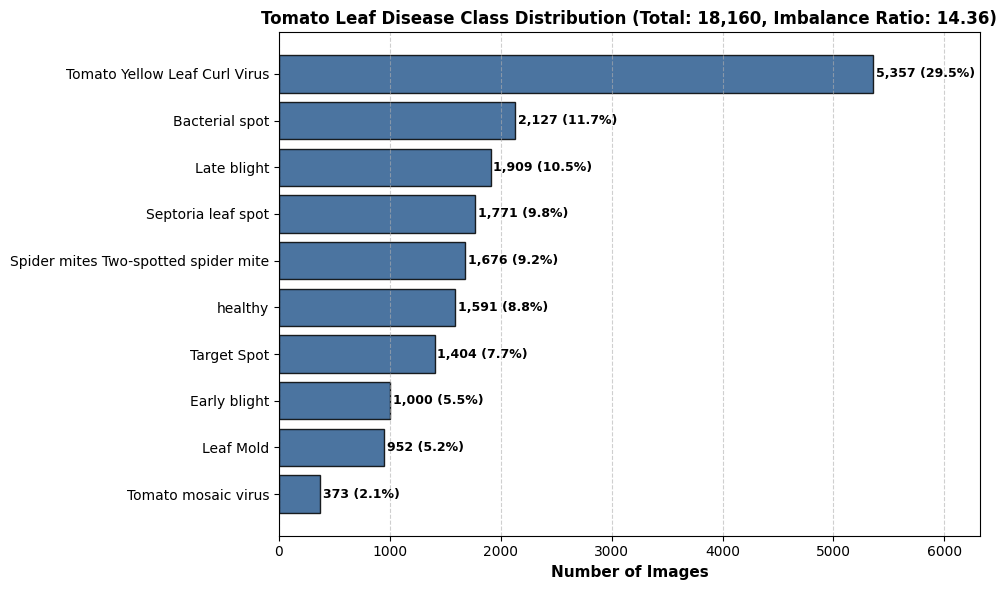


--- Diagnostic 2: Image Integrity, Dimensions & Color Modes ---
Corrupt / Unreadable Files: 0
Image Dimension Distribution (Width x Height):
  256 x 256: 18,160 images (100.0%)
Color Mode Distribution:
  RGB: 18,160 images (100.0%)
Aspect Ratio Distribution (Width / Height):
  1.0: 18,160 images (100.0%)

--- Diagnostic 3: Exact (MD5) & Perceptual (dHash) Duplicate Audit ---
Exact Duplicate Hash Sets:   14 (affecting 28 images)
  - Within-Class Duplicates: 14 sets
  - Cross-Class Conflicts:   0 sets (CRITICAL LABEL NOISE!)

Perceptual Near-Duplicates:  15 sets (affecting 30 images)
  - Within-Class Near-Dups:  15 sets
  - Cross-Class Near-Dups:   0 sets

[LEAKAGE GUARD] Duplicate hashes stored in dataset_records for group-aware splitting in Milestone 3.

--- Diagnostic 4: Filename Structure & Source Metadata Audit ---
Representative Filenames:
  6452c618-9439-42d8-ae0b-f0997e05ec35___Com.G_SpM_FL 1155.JPG
  527b81a0-f304-40ec-bfb3-987bbdde36b3___Com.G_SpM_FL 9459.JPG
  0f4e562d-77ee-4

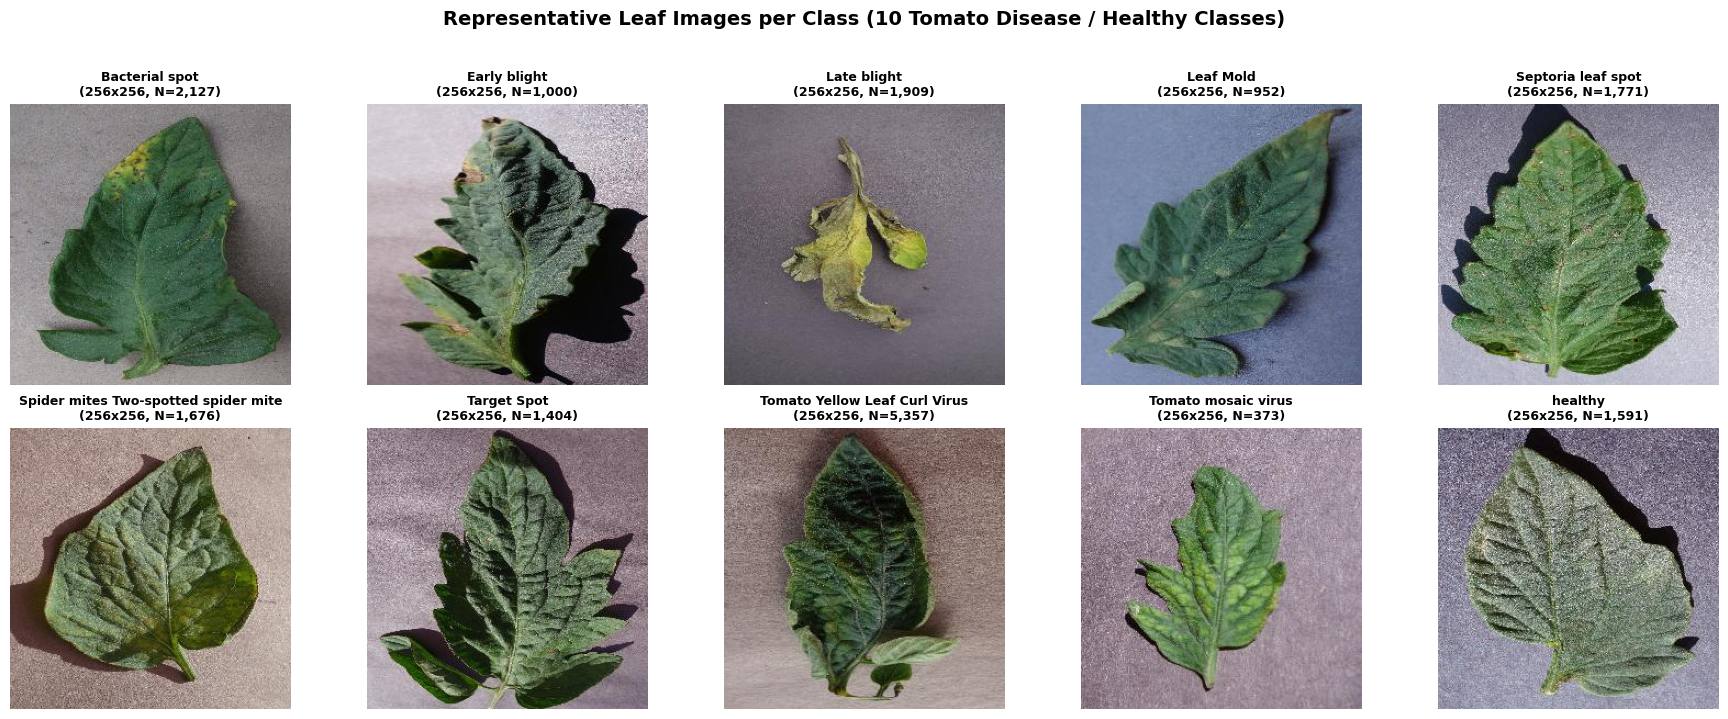

Computing Center vs. Border RGB Statistics (foreground vs. background luminance & color casts)...

Center vs. Border RGB Statistical Profile (Sampled up to 100 images/class):
                          class_name  center_mean_rgb  center_std_rgb  border_mean_rgb  border_std_rgb  border_center_diff   border_R   border_G   border_B
                      Bacterial spot        81.150002       30.540001       123.870003       28.670000           42.720001 127.660004 122.910004 121.050003
                        Early blight        82.419998       41.730000       130.949997       41.299999           48.520000 133.649994 129.639999 129.550003
                         Late blight        99.500000       43.400002       122.989998       34.369999           23.480000 125.699997 121.360001 121.900002
                           Leaf Mold        93.199997       40.730000       131.570007       30.549999           38.380001 127.910004 125.989998 140.809998
                  Septoria leaf spot       10

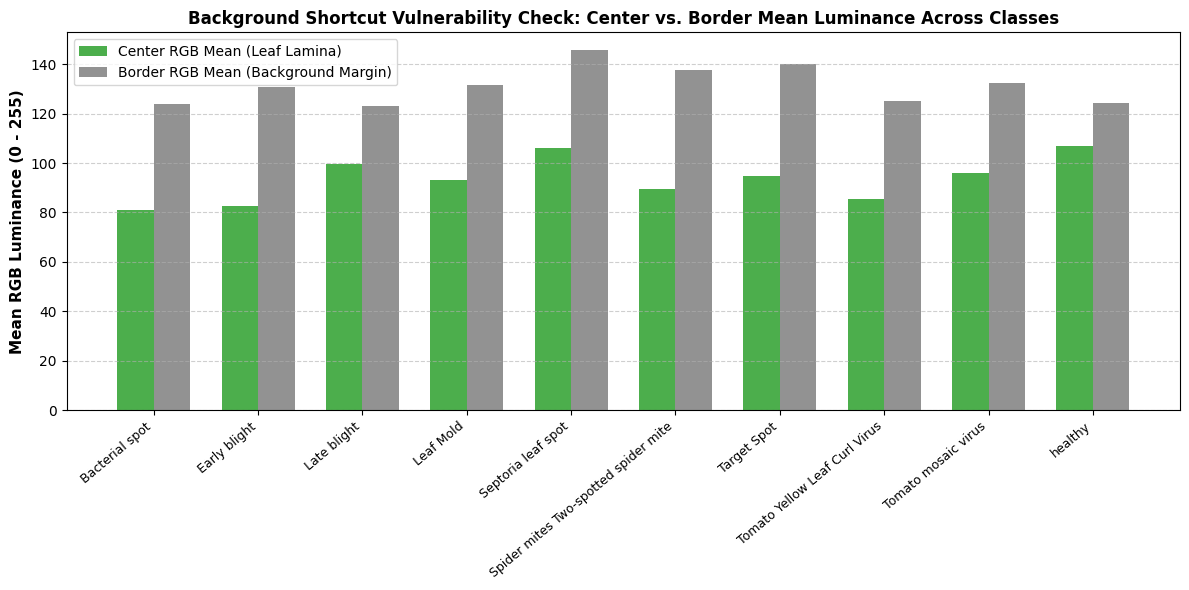


EDA complete. All 5 diagnostics generated successfully.


In [3]:
import os
import sys
import re
import hashlib
from collections import Counter
import random

# Verify optional analytical packages
try:
    import numpy as np
except ImportError:
    np = None

try:
    import pandas as pd
except ImportError:
    pd = None

try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None

try:
    from PIL import Image
except ImportError:
    Image = None

# ==============================================================================
# SECTION 4: Exploratory Data Analysis (EDA) Pipeline
# ==============================================================================

def run_exploratory_data_analysis(records_df, seed=42):
    """
    Executes the 5-point scientific exploratory data analysis on dataset_records.
    """
    if records_df is None or len(records_df) == 0:
        print("[NOTICE] 'dataset_records' is empty. EDA requires an acquired dataset.")
        print("Please execute Section 3 in Google Colab (or provide a local dataset path) first.")
        return records_df

    if np is None or pd is None or plt is None or Image is None:
        print("[NOTICE] Analytical dependencies (numpy, pandas, matplotlib, pillow) are required for EDA.")
        print("These packages are pre-installed in Google Colab.")
        return records_df

    print("=" * 65)
    print("EXPLORATORY DATA ANALYSIS (5-POINT DIAGNOSTIC)")
    print("=" * 65)

    # --------------------------------------------------------------------------
    # 1. Class Distribution & Imbalance Analysis
    # --------------------------------------------------------------------------
    print("\n--- Diagnostic 1: Class Distribution & Imbalance Analysis ---")
    class_counts = records_df.groupby("class_name").size().sort_values(ascending=False)
    total_images = len(records_df)
    min_count = class_counts.min()
    max_count = class_counts.max()
    imbalance_ratio = max_count / min_count

    print(f"Total Samples:     {total_images:,}")
    print(f"Number of Classes: {len(class_counts)}")
    print(f"Mean Class Size:   {class_counts.mean():.1f}")
    print(f"Median Class Size: {class_counts.median():.1f}")
    print(f"Min Class Size:    {min_count:,} ({class_counts.idxmin()})")
    print(f"Max Class Size:    {max_count:,} ({class_counts.idxmax()})")
    print(f"Imbalance Ratio:   {imbalance_ratio:.2f} (max/min)")

    # Plot horizontal bar chart
    fig, ax = plt.subplots(figsize=(10, 6))
    bars = ax.barh(class_counts.index, class_counts.values, color="#2b5c8f", edgecolor="black", alpha=0.85)
    ax.set_xlabel("Number of Images", fontsize=11, fontweight="bold")
    ax.set_title(f"Tomato Leaf Disease Class Distribution (Total: {total_images:,}, Imbalance Ratio: {imbalance_ratio:.2f})",
                 fontsize=12, fontweight="bold")
    ax.invert_yaxis()
    ax.grid(axis="x", linestyle="--", alpha=0.6)

    # Add count and percentage labels on bars
    for bar in bars:
        width = bar.get_width()
        pct = (width / total_images) * 100
        ax.text(width + 25, bar.get_y() + bar.get_height() / 2, f"{int(width):,} ({pct:.1f}%)",
                va="center", ha="left", fontsize=9, fontweight="bold")

    ax.set_xlim(0, max_count * 1.18)
    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------------------------
    # 2. Image Integrity, Dimensions, Aspect Ratios & Color Modes
    # --------------------------------------------------------------------------
    print("\n--- Diagnostic 2: Image Integrity, Dimensions & Color Modes ---")
    corrupt_count = 0
    dimensions = []
    aspect_ratios = []
    color_modes = []

    for path in records_df["filepath"]:
        try:
            with Image.open(path) as img:
                w, h = img.size
                dimensions.append((w, h))
                aspect_ratios.append(round(w / h, 4))
                color_modes.append(img.mode)
        except Exception:
            corrupt_count += 1

    print(f"Corrupt / Unreadable Files: {corrupt_count}")
    dim_counter = Counter(dimensions)
    mode_counter = Counter(color_modes)
    aspect_counter = Counter(aspect_ratios)

    print("Image Dimension Distribution (Width x Height):")
    for dim, count in dim_counter.most_common(5):
        print(f"  {dim[0]} x {dim[1]}: {count:,} images ({count / total_images * 100:.1f}%)")

    print("Color Mode Distribution:")
    for mode, count in mode_counter.items():
        print(f"  {mode}: {count:,} images ({count / total_images * 100:.1f}%)")

    print("Aspect Ratio Distribution (Width / Height):")
    for ar, count in aspect_counter.most_common(3):
        print(f"  {ar}: {count:,} images ({count / total_images * 100:.1f}%)")

    # --------------------------------------------------------------------------
    # 3. Exact & Near-Duplicate Leakage Audit
    # --------------------------------------------------------------------------
    print("\n--- Diagnostic 3: Exact (MD5) & Perceptual (dHash) Duplicate Audit ---")
    md5_hashes = []
    dhashes = []

    for path in records_df["filepath"]:
        # MD5 Hash of raw bytes
        try:
            with open(path, "rb") as f:
                md5 = hashlib.md5(f.read()).hexdigest()
        except Exception:
            md5 = None
        md5_hashes.append(md5)

        # 64-bit dHash (9x8 grayscale horizontal gradient)
        try:
            with Image.open(path) as img:
                gray = img.convert("L").resize((9, 8), resample=Image.Resampling.BILINEAR)
                pixels = np.array(gray)
                diff = pixels[:, 1:] > pixels[:, :-1]
                # Pack 64 boolean values into 16-character hex string
                dhash_int = sum(int(b) << i for i, b in enumerate(diff.flatten()))
                dhash_hex = f"{dhash_int:016x}"
        except Exception:
            dhash_hex = None
        dhashes.append(dhash_hex)

    records_df["md5_hash"] = md5_hashes
    records_df["dhash"] = dhashes

    # Audit Exact MD5 duplicates
    exact_hash_counts = records_df["md5_hash"].value_counts()
    exact_duplicate_hashes = exact_hash_counts[exact_hash_counts > 1].index
    num_exact_duplicates = len(exact_duplicate_hashes)
    exact_duplicate_images = exact_hash_counts[exact_hash_counts > 1].sum()

    exact_same_class = 0
    exact_cross_class = 0
    for h_val in exact_duplicate_hashes:
        classes_with_hash = records_df[records_df["md5_hash"] == h_val]["class_name"].nunique()
        if classes_with_hash > 1:
            exact_cross_class += 1
        else:
            exact_same_class += 1

    print(f"Exact Duplicate Hash Sets:   {num_exact_duplicates:,} (affecting {exact_duplicate_images:,} images)")
    print(f"  - Within-Class Duplicates: {exact_same_class:,} sets")
    print(f"  - Cross-Class Conflicts:   {exact_cross_class:,} sets (CRITICAL LABEL NOISE!)")

    # Detail cross-class exact duplicate pairs if detected
    if exact_cross_class > 0:
        print("\n  [ALERT] Cross-Class Exact Duplicates Detected (Label Noise / Mislabeling):")
        conflicts_shown = 0
        for h_val in exact_duplicate_hashes:
            sub = records_df[records_df["md5_hash"] == h_val]
            classes_in_hash = sub["class_name"].unique()
            if len(classes_in_hash) > 1:
                print(f"    - MD5 {h_val[:10]}... shared across classes: {list(classes_in_hash)}")
                for _, r in sub.head(3).iterrows():
                    print(f"        * [{r['class_name']}] {r['filename']}")
                conflicts_shown += 1
                if conflicts_shown >= 5:
                    if exact_cross_class > 5:
                        print(f"        ... and {exact_cross_class - 5} more conflicting exact duplicate hash sets.")
                    break

    # Audit Perceptual dHash near-duplicates
    dhash_counts = records_df["dhash"].value_counts()
    dhash_duplicate_hashes = dhash_counts[dhash_counts > 1].index
    num_dhash_duplicates = len(dhash_duplicate_hashes)
    dhash_duplicate_images = dhash_counts[dhash_counts > 1].sum()

    dhash_same_class = 0
    dhash_cross_class = 0
    for dh_val in dhash_duplicate_hashes:
        classes_with_dhash = records_df[records_df["dhash"] == dh_val]["class_name"].nunique()
        if classes_with_dhash > 1:
            dhash_cross_class += 1
        else:
            dhash_same_class += 1

    print(f"\nPerceptual Near-Duplicates:  {num_dhash_duplicates:,} sets (affecting {dhash_duplicate_images:,} images)")
    print(f"  - Within-Class Near-Dups:  {dhash_same_class:,} sets")
    print(f"  - Cross-Class Near-Dups:   {dhash_cross_class:,} sets")

    # Detail cross-class perceptual near-duplicate pairs if detected
    if dhash_cross_class > 0:
        print("\n  [ALERT] Cross-Class Perceptual Near-Duplicates Detected:")
        conflicts_shown = 0
        for dh_val in dhash_duplicate_hashes:
            sub = records_df[records_df["dhash"] == dh_val]
            classes_in_dhash = sub["class_name"].unique()
            if len(classes_in_dhash) > 1:
                print(f"    - dHash {dh_val} shared across classes: {list(classes_in_dhash)}")
                for _, r in sub.head(3).iterrows():
                    print(f"        * [{r['class_name']}] {r['filename']}")
                conflicts_shown += 1
                if conflicts_shown >= 5:
                    if dhash_cross_class > 5:
                        print(f"        ... and {dhash_cross_class - 5} more conflicting near-duplicate hash sets.")
                    break

    print("\n[LEAKAGE GUARD] Duplicate hashes stored in dataset_records for group-aware splitting in Milestone 3.")

    # --------------------------------------------------------------------------
    # 4. Filename Structure & Capture-Station / Specimen Metadata Audit
    # --------------------------------------------------------------------------
    print("\n--- Diagnostic 4: Filename Structure & Source Metadata Audit ---")
    sample_fnames = records_df["filename"].sample(min(5, len(records_df)), random_state=seed).tolist()
    print("Representative Filenames:")
    for fn in sample_fnames:
        print(f"  {fn}")

    # Parse prefix tokens after delimiter '___' and clean specimen ID
    source_prefixes = []
    aug_suffixes = []
    specimen_keys = []
    aug_keywords = {"flip", "copy", "deg", "new", "rot"}

    for _, row in records_df.iterrows():
        fn = row["filename"]
        raw_cls = row["raw_class"]

        # Capture prefix after '___'
        if "___" in fn:
            after_delim = fn.split("___", 1)[1]
            token = after_delim.split("_")[0].split(" ")[0].split(".")[0]
            source_prefixes.append(token)

            # Normalize specimen ID by stripping known augmentation suffixes and file extension
            base_part = os.path.splitext(after_delim)[0]
            clean_specimen = re.sub(r'(_flip(tb|lr)?|_\d+deg|_copy\d*|_new\d*|\(\d+\))$', '', base_part, flags=re.IGNORECASE).strip()
            specimen_keys.append(f"{raw_cls}::{clean_specimen}")
        else:
            source_prefixes.append("UNKNOWN")
            base_part = os.path.splitext(fn)[0]
            clean_specimen = re.sub(r'(_flip(tb|lr)?|_\d+deg|_copy\d*|_new\d*|\(\d+\))$', '', base_part, flags=re.IGNORECASE).strip()
            specimen_keys.append(f"{raw_cls}::{clean_specimen}")

        lower_fn = fn.lower()
        has_aug = any(kw in lower_fn for kw in aug_keywords)
        aug_suffixes.append(has_aug)

    records_df["source_prefix"] = source_prefixes
    records_df["has_aug_suffix"] = aug_suffixes
    records_df["specimen_key"] = specimen_keys

    print(f"\nUnique Source / Station Prefixes Discovered: {records_df['source_prefix'].nunique()}")
    print("Top 5 Source Prefixes:")
    for pfx, cnt in records_df["source_prefix"].value_counts().head(5).items():
        print(f"  {pfx}: {cnt:,} images ({cnt / total_images * 100:.1f}%)")

    # Cross-tabulation: class_name vs. Top 8 Source Prefixes (plus OTHER)
    top8_prefixes = records_df["source_prefix"].value_counts().head(8).index.tolist()
    prefix_binned = records_df["source_prefix"].apply(lambda x: x if x in top8_prefixes else "OTHER")
    ct = pd.crosstab(records_df["class_name"], prefix_binned, margins=True, margins_name="Total")
    print("\nCross-Tabulation: Disease Class vs. Top Source/Capture Prefixes:")
    print(ct.to_string())

    aug_cnt = sum(aug_suffixes)
    print(f"\nImages with Potential Augmentation Suffixes (flip/deg/copy): {aug_cnt:,} ({aug_cnt / total_images * 100:.1f}%)")

    # Specimen ID clustering audit
    specimen_counts = records_df["specimen_key"].value_counts()
    multiview_specimens = specimen_counts[specimen_counts > 1]
    multiview_images = multiview_specimens.sum()
    print(f"\nSpecimen Key Clustering Audit:")
    print(f"  - Total Unique Specimen Keys: {len(specimen_counts):,}")
    print(f"  - Specimens with Multiple Images/Views: {len(multiview_specimens):,} keys (affecting {multiview_images:,} images)")
    if len(multiview_specimens) > 0:
        max_views = multiview_specimens.max()
        print(f"  - Maximum Images per Single Specimen Key: {max_views}")
        print("  - Top 3 Specimen Keys with Most Views:")
        for sk, cnt in multiview_specimens.head(3).items():
            print(f"      * {sk}: {cnt} images")
    print("[LEAKAGE GUARD] 'specimen_key' stored in dataset_records for group-level split isolation in Milestone 3.")

    # --------------------------------------------------------------------------
    # 5. Visual Sample Gallery & Center vs. Border RGB Statistics
    # --------------------------------------------------------------------------
    print("\n--- Diagnostic 5: Visual Sample Gallery & Center vs. Border RGB Profiling ---")

    classes_sorted = sorted(records_df["class_name"].unique())
    fig, axes = plt.subplots(2, 5, figsize=(18, 7))
    axes = axes.flatten()

    for i, c_name in enumerate(classes_sorted):
        c_records = records_df[records_df["class_name"] == c_name]
        sample_row = c_records.sample(1, random_state=seed).iloc[0]
        with Image.open(sample_row["filepath"]) as img:
            axes[i].imshow(img)
            axes[i].set_title(f"{c_name}\n({img.size[0]}x{img.size[1]}, N={len(c_records):,})",
                              fontsize=9, fontweight="bold")
            axes[i].axis("off")

    plt.suptitle("Representative Leaf Images per Class (10 Tomato Disease / Healthy Classes)",
                 fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

    # Stratified Center vs. Border RGB statistical profile (up to 100 images per class)
    print("Computing Center vs. Border RGB Statistics (foreground vs. background luminance & color casts)...")
    stats_records = []

    for c_name in classes_sorted:
        c_sub = records_df[records_df["class_name"] == c_name]
        sample_subset = c_sub.sample(min(100, len(c_sub)), random_state=seed)

        center_means = []
        center_stds = []
        border_means = []
        border_stds = []
        border_r_vals = []
        border_g_vals = []
        border_b_vals = []

        for p in sample_subset["filepath"]:
            try:
                with Image.open(p) as img:
                    arr = np.array(img.convert("RGB"), dtype=np.float32)
                    h, w, _ = arr.shape

                    # Central 60% crop (foreground proxy)
                    c_h_start, c_h_end = int(h * 0.2), int(h * 0.8)
                    c_w_start, c_w_end = int(w * 0.2), int(w * 0.8)
                    center_pixels = arr[c_h_start:c_h_end, c_w_start:c_w_end]
                    center_means.append(center_pixels.mean())
                    center_stds.append(center_pixels.std())

                    # Outer 10% border margin (background proxy)
                    border_mask = np.ones((h, w), dtype=bool)
                    border_mask[int(h * 0.1):int(h * 0.9), int(w * 0.1):int(w * 0.9)] = False
                    border_pixels = arr[border_mask]

                    border_means.append(border_pixels.mean())
                    border_stds.append(border_pixels.std())
                    border_r_vals.append(border_pixels[:, 0].mean())
                    border_g_vals.append(border_pixels[:, 1].mean())
                    border_b_vals.append(border_pixels[:, 2].mean())
            except Exception:
                continue

        stats_records.append({
            "class_name": c_name,
            "center_mean_rgb": np.mean(center_means),
            "center_std_rgb": np.mean(center_stds),
            "border_mean_rgb": np.mean(border_means),
            "border_std_rgb": np.mean(border_stds),
            "border_center_diff": np.mean(border_means) - np.mean(center_means),
            "border_R": np.mean(border_r_vals),
            "border_G": np.mean(border_g_vals),
            "border_B": np.mean(border_b_vals),
        })

    stats_df = pd.DataFrame(stats_records)
    print("\nCenter vs. Border RGB Statistical Profile (Sampled up to 100 images/class):")
    print(stats_df.round(2).to_string(index=False))

    # Plot grouped bar chart comparing Center vs. Border Mean RGB
    fig, ax = plt.subplots(figsize=(12, 6))
    x = np.arange(len(stats_df))
    width = 0.35

    ax.bar(x - width/2, stats_df["center_mean_rgb"], width, label="Center RGB Mean (Leaf Lamina)", color="#2ca02c", alpha=0.85)
    ax.bar(x + width/2, stats_df["border_mean_rgb"], width, label="Border RGB Mean (Background Margin)", color="#7f7f7f", alpha=0.85)

    ax.set_ylabel("Mean RGB Luminance (0 - 255)", fontsize=11, fontweight="bold")
    ax.set_title("Background Shortcut Vulnerability Check: Center vs. Border Mean Luminance Across Classes",
                 fontsize=12, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(stats_df["class_name"], rotation=40, ha="right", fontsize=9)
    ax.legend(fontsize=10)
    ax.grid(axis="y", linestyle="--", alpha=0.6)
    plt.tight_layout()
    plt.show()

    print("\nEDA complete. All 5 diagnostics generated successfully.")
    print("=" * 65)
    return records_df


# --- Run EDA Pipeline ---
if "dataset_records" in locals() and len(dataset_records) > 0:
    dataset_records = run_exploratory_data_analysis(dataset_records, seed=SEED)
else:
    print("[NOTICE] Section 4 EDA pipeline ready. Execute Section 3 first to acquire dataset records.")

# 5. Dataset Splitting

### Purpose
Partition the dataset into Training (70%), Validation (15%), and Test (15%) subsets using stratified splitting to preserve class proportions. Ensure strict split isolation and zero data leakage across splits using a fixed random seed.

### Split Responsibilities & Methodology
- **Target Planned Ratio:** 70% Training, 15% Validation, 15% Test.
- **Strict Role Separation:**
  - **Training split (70%):** Model parameter optimization and feature learning.
  - **Validation split (15%):** Model selection, hyperparameter tuning, validation error analysis, Grad-CAM failure diagnosis, hypothesis testing, and confidence calibration parameter fitting (e.g., Temperature Scaling).
  - **Test split (15%):** Strictly untouched holdout partition reserved solely for final unbiased benchmark evaluation (Section 9 Baseline Evaluation and Section 14 Before/After Comparison).
- **Data Integrity & Leakage Prevention:** The final partitioning strategy and checks for near-duplicate images or sample groupings will be informed by the exploratory data analysis findings in Milestone 2.

In [ ]:
# [Placeholder: Milestone 3]
# Reproducible, stratified dataset partitioning will be implemented here.
# Enforces strict split isolation: Training (70%), Validation (15%), Test (15%).
print("Section 5: Dataset Splitting scaffold ready.")

# 6. Data Pipeline and Augmentation

### Purpose
Construct high-performance input pipelines using `tf.data.Dataset`. Apply input rescaling/normalization and configure domain-appropriate data augmentations (flips, rotations, zooms) designed to prevent overfitting while preserving pathological leaf lesions.

In [ ]:
# [Placeholder: Milestone 3]
# tf.data.Dataset pipelines with batching, prefetching (AUTOTUNE),
# normalization, and augmentation layers will be implemented here.
print("Section 6: Data Pipeline and Augmentation scaffold ready.")

# 7. Baseline CNN Architecture

### Purpose
Design and construct a clean, modular baseline Convolutional Neural Network (CNN) in `tf.keras`. Define the convolutional feature extractor, pooling layers, regularization mechanisms (Dropout/BatchNormalization), and dense classification head for 10-class output.

In [ ]:
# [Placeholder: Milestone 4]
# Baseline CNN architecture construction and model.summary() will be implemented here.
# Configures loss, optimizer, and performance metrics.
print("Section 7: Baseline CNN Architecture scaffold ready.")

# 8. Baseline Training

### Purpose
Execute baseline model training with monitoring callbacks (`EarlyStopping`, `ReduceLROnPlateau`, and `ModelCheckpoint`). Log loss and accuracy progression curves across training and validation splits.

In [ ]:
# [Placeholder: Milestone 4]
# Baseline model training loop with callbacks and epoch curve visualization.
print("Section 8: Baseline Training scaffold ready.")

# 9. Baseline Evaluation

### Purpose
Perform comprehensive quantitative evaluation on the unseen holdout test set. Generate accuracy metrics, per-class Precision, Recall, and F1-scores via classification reports, and plot the multi-class Confusion Matrix.

In [ ]:
# [Placeholder: Milestone 5]
# Quantitative test evaluation, classification report, and confusion matrix.
print("Section 9: Baseline Evaluation scaffold ready.")

# 10. Grad-CAM Implementation

### Purpose
Implement the Gradient-weighted Class Activation Mapping (Grad-CAM) algorithm from first principles in TensorFlow/Keras. Extract gradients of the target class score with respect to the final convolutional feature maps, compute importance pooling weights, generate 2D class-discriminative localization heatmaps, and overlay them onto input leaf images.

In [ ]:
# [Placeholder: Milestone 6]
# Grad-CAM computation function, heatmap generation, and overlay visualization.
print("Section 10: Grad-CAM Implementation scaffold ready.")

# 11. Failure Diagnosis and Hypothesis

### Purpose
Perform visual and quantitative error analysis exclusively on the **validation set** using Grad-CAM class-discriminative localization and feature importance heatmaps. Formulate a rigorous, evidence-based research hypothesis grounded in observed failure patterns.

### Diagnostic Protocol (Validation-Only Isolation)
- **Zero Test Set Leakage:** To ensure unbiased benchmark reporting, all error analysis, diagnostic visualization, and hypothesis generation are strictly confined to the **validation split**. The holdout test set remains completely untouched.
- **Post-Hoc Spatial Attribution:** Grad-CAM produces gradient-weighted class activation heatmaps that highlight which spatial regions of an image most strongly influence the final convolutional representations for a target class.
- **Empirical Failure Discovery:** Rather than assuming a single preconceived failure mode, we will systematically examine validation failure modes across multiple candidate hypotheses, including:
  1. *Spurious correlation / shortcut learning:* Model relies on background boards, paper tags, or border artifacts.
  2. *Inter-class morphological confusion:* Lesion visual similarity between diseases (e.g., Early Blight vs. Late Blight).
  3. *Lesion scale & resolution loss:* Inability of downsampled feature maps to capture small, early-stage punctate spots.
  4. *Illumination and shadow sensitivity:* Strong specular highlights or dark leaf folds skewing activation weights.
  5. *Class imbalance artifacts:* Bias towards majority disease classes on ambiguous samples.
- The empirical evidence from validation errors will directly determine the formal hypothesis logged in the Experiment Journal.

In [ ]:
# [Placeholder: Milestone 6]
# Validation-set diagnostic visualization grid and systematic hypothesis logging.
# Uses Grad-CAM class-discriminative localization heatmaps on validation errors.
print("Section 11: Failure Diagnosis and Hypothesis scaffold ready.")

# 12. Hypothesis Verification and Targeted Fix

### Purpose
Design an empirical verification experiment on the **validation split** to test the hypothesis formulated in Section 11, and introduce a targeted methodological intervention designed to mitigate the diagnosed failure mode.

### Verification & Intervention Methodology
- **Hypothesis Testing:** Evaluate the specific failure mechanism using controlled tests on the validation set (e.g., background invariance testing, synthetic masking, or perturbation analysis).
- **Targeted Methodological Intervention:** Formulate a principled fix directly addressing the confirmed vulnerability. Depending on empirical findings, interventions may include:
  - *Domain-specific data augmentation* (e.g., aggressive background variation, color/contrast jittering, random erasing).
  - *Input preprocessing adaptations* (e.g., leaf-focused cropping or background suppression).
  - *Architectural or regularization adjustments* (e.g., spatial dropout, weight regularization, modified receptive fields).
- The intervention will be locked in before retraining the improved model under identical evaluation conditions.

In [ ]:
# [Placeholder: Milestone 7]
# Hypothesis verification tests and targeted methodological intervention implementation.
# Conducted strictly on the validation set to preserve holdout test integrity.
print("Section 12: Hypothesis Verification and Targeted Fix scaffold ready.")

# 13. Improved Model Training and Evaluation

### Purpose
Train the improved model incorporating the targeted intervention under strictly identical train/val/test splits and training constraints. Evaluate its performance on the holdout test set.

In [ ]:
# [Placeholder: Milestone 7]
# Improved model training and quantitative test evaluation.
print("Section 13: Improved Model Training and Evaluation scaffold ready.")

# 14. Before/After Comparison

### Purpose
Perform a rigorous comparative evaluation between the Baseline CNN and the Improved Model across both quantitative performance metrics and qualitative spatial attribution alignment.

### Comparative Evaluation Protocol
1. **Quantitative Performance:** Evaluate both models on the unseen holdout **test split** across identical evaluation criteria: Overall Accuracy, Macro-averaged Precision, Recall, F1-Score, and class-specific error reductions.
2. **Qualitative Spatial Attribution Alignment:** Compare side-by-side Grad-CAM feature importance heatmaps on representative samples to demonstrate whether the targeted intervention successfully shifted the network's class-discriminative localization onto genuine pathological symptoms (e.g., necrotic lesions, chlorotic margins, fungal sporulation) rather than confounding features.

In [ ]:
# [Placeholder: Milestone 7]
# Side-by-side metric tables and visual Grad-CAM spatial attribution comparison grids.
print("Section 14: Before/After Comparison scaffold ready.")

# 15. Confidence Calibration and Trust Assessment

### Purpose
Evaluate model trustworthiness and probability reliability to ensure that confidence scores reflect true predictive accuracy. Compute calibration error metrics, plot reliability diagrams, and fit post-hoc calibration parameters exclusively using the **validation set**.

### Calibration Protocol & Split Separation
- **Validation Calibration Fitting:** Post-hoc calibration techniques (such as Temperature Scaling or Platt Scaling) optimize scaling parameters (e.g., temperature $T$) to align predicted softmax probabilities with empirical accuracy. This parameter optimization is performed strictly on the **validation split** to prevent overfitting the test set.
- **Holdout Test Trust Assessment:** Final calibration metrics—including Expected Calibration Error (ECE), Maximum Calibration Error (MCE), and Reliability Diagrams (calibration curves)—are reported on the unseen **test split** for both baseline and improved models.
- **Risk Assessment for Agricultural Deployment:** Analyze overconfidence on erroneous predictions to ensure the diagnostic system fails safely when encountering ambiguous or out-of-distribution field samples.

In [ ]:
# [Placeholder: Milestone 8]
# Validation-fitted temperature scaling, ECE calculation, and reliability curves.
print("Section 15: Confidence Calibration and Trust Assessment scaffold ready.")

# 16. Final Inference Tool

### Purpose
Package the final pipeline into a standalone, robust Python inference function. The function accepts an input leaf image, computes top-k predictions with calibrated confidence scores, and outputs a diagnostic Grad-CAM spatial attribution overlay.

In [ ]:
# [Placeholder: Milestone 9]
# Standalone inference function: predict_with_explanation(image_path_or_array).
print("Section 16: Final Inference Tool scaffold ready.")

# 17. Technical Report

### Purpose
Synthesize the complete project arc into an executive research technical report: methodology, quantitative and qualitative results, post-hoc spatial attribution insights, confidence calibration analysis, field deployment limitations, and practical recommendations for agronomists.

In [ ]:
# [Placeholder: Milestone 9]
# Executive technical summary, final metric synthesis, and deployment conclusions.
print("Section 17: Technical Report scaffold ready.")